# 7.1 Bayesian Statistics

**Goal:** connect Bayesian model components, conjugate updates, credible intervals, and hierarchical shrinkage.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Bayesian Statistics](1_Bayesian-Statistics.ipynb)
2. [Parameter Estimation](2_Parameter-Estimation.ipynb)
3. [Multivariate Statistics](3_Multivariate-Statistics.ipynb)
4. [Resampling Methods](4_Resampling-Methods.ipynb)
5. [Experimental Design](5_Experimental-Design.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Bayesian Inference: Prior and Posterior Distributions

Bayesian inference updates uncertainty about parameters using $p(\theta|D)=p(D|\theta)p(\theta)/p(D)$. The prior encodes pre-data information, the likelihood scores observed data under parameter values, and the evidence normalizes. A posterior is conditional on the entire model and cannot repair omitted hypotheses, selection bias, or misspecified measurements by normalization alone.

For **likelihood functions**, observations are fixed and the parameter varies. A likelihood need not integrate to one over parameters. For continuous observations it is often a density, not a point probability. With conditionally independent data, likelihood factors multiply; dependence requires the appropriate joint or conditional model.

## 2. Conjugate Priors and Bayesian Updating

A prior family is conjugate when updating with the chosen likelihood stays in that family. For IID Bernoulli observations with s successes and f failures, Beta(a,b) updates to Beta(a+s,b+f). A gamma **shape-rate** prior Gamma(a,b) for a Poisson rate λ updates to Gamma(a+Σy,b+Σt) when independent counts have means λtᵢ. Convert rate b to SciPy scale 1/b.

**Worked example:** Beta(2,2), 8 successes and 2 failures gives Beta(10,4). Posterior mean is 10/14; the next-trial predictive success probability equals this mean. A future count distribution additionally averages over parameter uncertainty, so it is not always the same as plugging that mean into a fixed-parameter count model.

In [2]:
post=stats.beta(10,4)
print("Posterior mean:",post.mean(),"95% equal-tail interval:",post.ppf([.025,.975]))
counts=np.array([2,4,3]);exposures=np.array([1.,2.,1.])
shape,rate=2+counts.sum(),1+exposures.sum()
print("Gamma shape-rate posterior:",shape,rate,"mean rate:",shape/rate)

Posterior mean: 0.7142857142857143 95% equal-tail interval: [0.46186846 0.90907961]
Gamma shape-rate posterior: 11 5.0 mean rate: 2.2


## 3. Bayesian Estimation and Bayesian Credible Intervals

A Bayes estimate minimizes posterior expected loss. Squared-error loss gives the posterior mean, absolute-error loss a posterior median, and a mode can arise under a suitable limiting local loss; MAP is parameterization-dependent. An equal-tail 95% credible interval puts 2.5% posterior mass on each side. A highest-density credible region can differ and can be disconnected for multimodal posteriors.

Credible intervals assign posterior probability under the specified prior/likelihood. Frequentist coverage is a separate property. Posterior predictive checks simulate data from the fitted model and compare relevant features; success does not prove the model correct, and checking the same data can have limited sensitivity.

Posterior mean / median / interior mode: 0.7142857142857143 0.7247241675138478 0.75


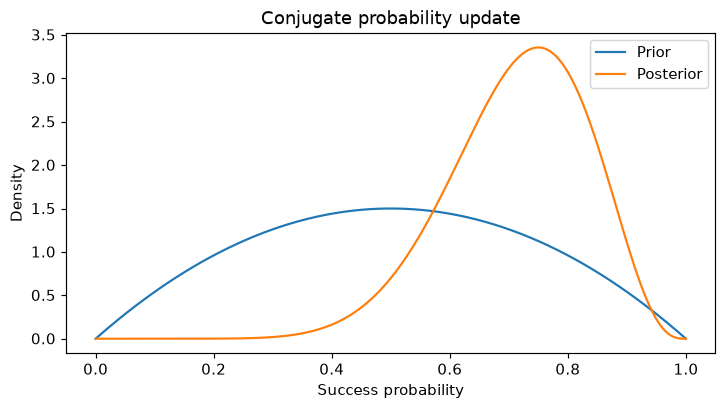

In [3]:
print("Posterior mean / median / interior mode:",post.mean(),post.median(),(10-1)/(10+4-2))
grid=np.linspace(0,1,401)
fig,ax=plt.subplots();ax.plot(grid,stats.beta(2,2).pdf(grid),label="Prior");ax.plot(grid,post.pdf(grid),label="Posterior")
ax.set(title="Conjugate probability update",xlabel="Success probability",ylabel="Density");ax.legend()
fig.tight_layout();plt.show()

## 4. Bayesian Hypothesis Testing

For models M₁,M₀, posterior odds equal prior odds times the **Bayes factor** $p(D|M_1)/p(D|M_0)$. Evidence averages likelihood over each model's proper parameter prior, not merely its best-fitting likelihood. Bayes factors can be sensitive to prior scale; improper priors generally cannot be used casually for evidence comparisons. A point null can receive nonzero posterior probability only if the prior model assigns it mass.

**Example:** compare a fair coin point model with an alternative p∼Beta(1,1). For an observed ordered sequence with 8 heads and 2 tails, alternative evidence is B(9,3)/B(1,1); null evidence is .5¹⁰. Using a count likelihood multiplies both by the same combination factor, which cancels from their ratio.

In [4]:
s,f=8,2
log_alt=special.betaln(1+s,1+f)-special.betaln(1,1)
log_null=(s+f)*np.log(.5)
bf=np.exp(log_alt-log_null)
print("Bayes factor alternative/fair:",bf,"posterior alternative under equal model priors:",bf/(1+bf))

Bayes factor alternative/fair: 2.0686868686868687 posterior alternative under equal model priors: 0.67412771560237


## 5. Hierarchical Bayesian Models

A hierarchy shares information across related groups: $\theta_j\sim N(\mu,\tau²)$ and $\bar Y_j|\theta_j\sim N(\theta_j,\sigma²/n_j)$. With μ,τ,σ treated as known, posterior group means shrink toward μ by weight $w_j=\tau²/(\tau²+\sigma²/n_j)$. Smaller groups shrink more because their direct estimates are noisier.

A fully Bayesian hierarchy puts priors on unknown hyperparameters and integrates their uncertainty. Estimating hyperparameters from data and plugging them in is empirical Bayes, a different approximation. Group exchangeability, prior choice, and predictive checks matter; pooling unrelated groups can harm inference.

In [5]:
raw=np.array([2.,-1.,.8]);sizes=np.array([3,30,300]);mu,tau,sigma=0.,1.,2.
weights=tau**2/(tau**2+sigma**2/sizes)
print("Known-hyperparameter shrinkage weights:",weights)
print("Partially pooled group means:",weights*raw+(1-weights)*mu)

Known-hyperparameter shrinkage weights: [0.42857143 0.88235294 0.98684211]
Partially pooled group means: [ 0.85714286 -0.88235294  0.78947368]


## AI/ML application and interpretation

Bayesian ML uses posterior prediction for uncertainty and model averaging. Keep parameter uncertainty distinct from new-outcome noise and deployment mismatch. A concentrated posterior from a wrong independence model can be overconfident; hierarchical structures and posterior checks should reflect users, sites, or repeated measurements.

## Practice

1. Beta(3,5) plus 4 successes and 6 failures gives which posterior?
2. Which posterior estimate minimizes squared-error loss?
3. Does a credible interval automatically have exact frequentist coverage?
4. Why can small groups benefit from partial pooling?

## Solutions

1. Beta(7,11).
2. The posterior mean, when finite.
3. No. Coverage must be assessed separately under repeated sampling and the relevant parameter values/design.
4. Their noisy estimates borrow information under the hierarchy, reducing variance at the cost of model-dependent shrinkage.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](2_Parameter-Estimation.ipynb).